In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.transforms as mpltransforms
from matplotlib.lines import Line2D
import matplotlib.patches as mpatches

import seaborn as sns
import os
import datetime
import pickle
from scipy.signal import find_peaks

from astropy.stats.circstats import circvar, circmean
from scipy.stats import pearsonr
from statannotations.stats.StatTest import StatTest
from statsmodels.stats.proportion import proportions_ztest

from scipy.stats import ranksums, ttest_ind, ttest_1samp, f_oneway, false_discovery_control, wilcoxon, mannwhitneyu 
import statsmodels.regression as sm
from statannotations.Annotator import Annotator

from astropy.timeseries import LombScargle

In [3]:
if os.getcwd().endswith('/notebooks/figures'):
    os.chdir('../../')

In [4]:
# from src.dataproc import utils, ccutils
from src.model import kuramotoattractor, linearreg
from src.dataproc import ccutils, utils
from src.visualize import cycleviz

### Supporting functions

In [5]:
colornums = sns.color_palette(palette='Greens', n_colors=6, as_cmap=False)
greens_palette_hex = list(colornums.as_hex())

In [6]:
### common variables
osccolordict = {'left':'tab:blue', 'right':'tab:orange', 'stim':'tab:red', 'cday':'gold', 'cnight':'black'}
coupling_const_list = ['K_left_right', 'K_left_stim', 'K_left_cday', 'K_left_cnight', 
                       'K_right_left', 'K_right_stim', 'K_right_cday', 'K_right_cnight']

dayclus_peakphase = 15 * np.pi / 12
nightclus_peakphase = 3 * np.pi / 12
sunmarker = '$\u2600$'
moonmarker = '$\u263D$'

### read fitted coupling constants from files

In [7]:
save_flag = False

In [8]:
outfig_dir = 'output/circpaper_figures/fig06/'
outsupfig_dir = 'output/circpaper_figures/supp/'

In [9]:
attfile = 'data/processed/kuramotoattractor/fitted_couplings_attractor_24Sep2025.csv'
attbrfile = 'data/processed/kuramotoattractor/fitted_couplings_attractor_brain_24Sep2025.csv'
attbrstfile = 'data/processed/kuramotoattractor/fitted_couplings_attractor_brain_stim_24Sep2025.csv'

acoupdf = pd.read_csv(attfile, index_col='index')
abcoupdf = pd.read_csv(attbrfile, index_col='index')
abstcoupdf = pd.read_csv(attbrstfile, index_col='index')

# similarity scores for all the fitting functions
acoupdf['fc_sim_hr'] = acoupdf.apply(lambda row: kuramotoattractor.fc_similarity_hour(row), axis=1)
abcoupdf['fc_sim_hr'] = abcoupdf.apply(lambda row: kuramotoattractor.fc_similarity_hour(row), axis=1) 
abstcoupdf['fc_sim_hr'] = abstcoupdf.apply(lambda row: kuramotoattractor.fc_similarity_hour(row), axis=1) 

# dataframe with only the similarity scores for all the fitting functions
fcsimhrdf = pd.concat(( acoupdf['fc_sim_hr'].rename('attractor'), 
                        abcoupdf['fc_sim_hr'].rename('attractor_brain'), 
                        abstcoupdf['fc_sim_hr'].rename('attractor_brain_stim') ), 
                      axis=1, ignore_index=False)

In [10]:
### associate with outcome
longi_patcodes_path = 'data/RNSdata/Outcome/Hippo_longitudinal_outcomes_postprocessed_2025April08.csv'
lgpatcodesdf = pd.read_csv(longi_patcodes_path) # longitudinal outcomes

In [11]:
patient_list = ccutils.final_patient_list()

print('Num patients:', len(patient_list))

Num patients: 38


### 6C: Predicted trajectories examples

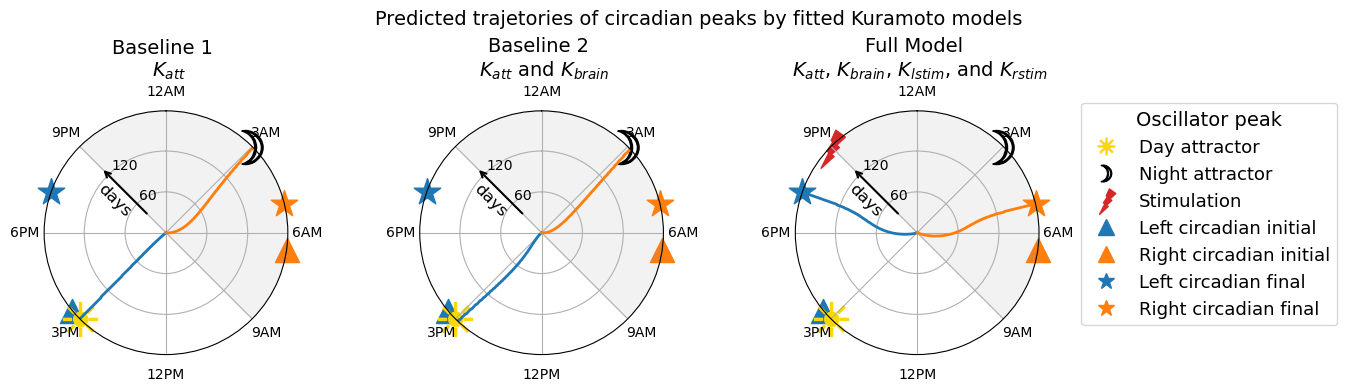

In [12]:
# check Kuramoto model forward solution for a given solution

df_index = 82 # 82
row_dict = {'attractor': acoupdf.loc[df_index], 
            'attractor_brain': abcoupdf.loc[df_index], 
            'attractor_brain_stim': abstcoupdf.loc[df_index]}
row_key_list = list(row_dict.keys())

traj_hue_dict = {'attractor': ['left', 'right'], 'attractor_brain': ['left', 'right'], 
                 'attractor_brain_stim': ['left', 'right']}
subtitle_dict = {'attractor': 'Baseline 1 \n $K_{att}$', 'attractor_brain': 'Baseline 2 \n $K_{att}$ and $K_{brain}$', 
                 'attractor_brain_stim': 'Full Model \n $K_{att}$, $K_{brain}$, $K_{lstim}$, and $K_{rstim}$'}
scaling_list = [80, 300, 5]  # change to [1,1,1] for non scaled version' [80, 300, 5] for index=82

ncols = 4
nrows = 1
fig, ax = plt.subplots(nrows, ncols, figsize=(3.6*ncols, 3.8*nrows), subplot_kw={'projection':'polar'}, layout='constrained')
fax = ax.flatten()

for ii in range(3):
    ### key and row
    row_key = row_key_list[ii]
    row = row_dict[row_key].copy()

    ### Kuramoto model forward solution
    # initial and final peak hours ground truth
    init_thetas = -1 * row[['left_peakphase_prev', 'right_peakphase_prev', 'stim_peakphase']] # negative sign so that the peak occurs at the correct phase
    init_thetas.rename(index={'left_peakphase_prev':'theta_left_0', 'right_peakphase_prev':'theta_right_0', 'stim_peakphase':'theta_stim_0'}, 
                       inplace=True)
    init_thetas = init_thetas.to_dict() | {'omega_0':2*np.pi}
    
    gt_theta_left_final = row['left_peakphase'].item()
    gt_theta_right_final = row['right_peakphase'].item()
    
    # fit coupling constants
    fitted_couplings = row[coupling_const_list].to_dict()
    scaled_fitted_couplings = ( pd.Series(fitted_couplings) / scaling_list[ii] ).to_dict()
    
    # run model forward with fitted coupling constants
    osppdf, outmat, clusmat, ssterm = kuramotoattractor.test_couplings_with_forward_model(theta_init_dict=init_thetas, 
                                                                                          coupling_dict=scaled_fitted_couplings)

    #### plot the trajectories
    cycleviz.kuramoto_forward_trajectories(osppdf, hue_list=traj_hue_dict[row_key], hue_colors=osccolordict,
                                           theta_left=-init_thetas['theta_left_0'], theta_right=-init_thetas['theta_right_0'], 
                                           fig=fig, ax=fax[ii], legend=False, markersize=300)
    
    # plot the final ground truth hour 
    rmax = fax[ii].get_rmax()
    fax[ii].scatter(gt_theta_left_final, rmax, s=400, c='tab:blue', marker='*', clip_on=False)
    fax[ii].scatter(gt_theta_right_final, rmax, s=400, c='tab:orange', marker='*', clip_on=False)

    fax[ii].scatter(dayclus_peakphase, rmax, s=600, c=osccolordict['cday'], marker=sunmarker, clip_on=False)
    fax[ii].scatter(nightclus_peakphase, rmax, s=600, c=osccolordict['cnight'], marker=moonmarker, clip_on=False)

    if row_key == 'attractor_brain_stim': fax[ii].scatter(-init_thetas['theta_stim_0'], rmax, s=900, c=osccolordict['stim'], marker=cycleviz.lightning_bolt(), clip_on=False)

    fax[ii].set_title(subtitle_dict[row_key], fontsize=14)
    fax[ii].set_yticks([60, 120])
    
    # draw an arrow from the center outward along the 9 PM direction
    fax[ii].set_rlabel_position(-42)
    theta_9pm_rad = 21 * np.pi/12
    fax[ii].annotate('', xy=(theta_9pm_rad, rmax * 0.75), xytext=(theta_9pm_rad, rmax * 0.20),
                      xycoords='data', textcoords='data', arrowprops=dict(arrowstyle='->', lw=1.5, color='black'))
    fax[ii].text(0.96*theta_9pm_rad, rmax * 0.50, 'days', ha='center', va='center', fontsize=12, rotation=-45)

fax[3].set_visible(False)
fig.suptitle(f'Predicted trajetories of circadian peaks by fitted Kuramoto models', fontsize=14)

### fancy legend
# Define the styles and the separate labels
markers = [sunmarker, moonmarker, cycleviz.lightning_bolt(), '^', '^', '*', '*']
colors = [osccolordict[key] for key in ['cday', 'cnight', 'stim', 'left', 'right', 'left', 'right']]
legend_labels = ['Day attractor', 'Night attractor', 'Stimulation', 'Left circadian initial', 'Right circadian initial', 
                 'Left circadian final', 'Right circadian final']

# Create a list to store the custom handles
custom_handles = []
for marker, color in zip(markers, colors):
    # Create a Line2D object with the desired properties
    if color == 'tab:red': markersize=20
    else: markersize=12
    handle = Line2D([0], [0], marker=marker, color=color, linestyle='', markersize=markersize, markerfacecolor=color)
    custom_handles.append(handle)

# We pass the manually created custom_handles and the separate legend_labels
fig.legend(custom_handles, legend_labels, fontsize=13, loc='center right', bbox_to_anchor=(0.95, 0.45), 
           title='Oscillator peak', title_fontsize=14, fancybox=True, shadow=False)

if save_flag:
    plt.savefig(outfig_dir + 'kuramoto_example.pdf', dpi=300)

plt.show()

### Supplementary: Predicted trajectories unscaled

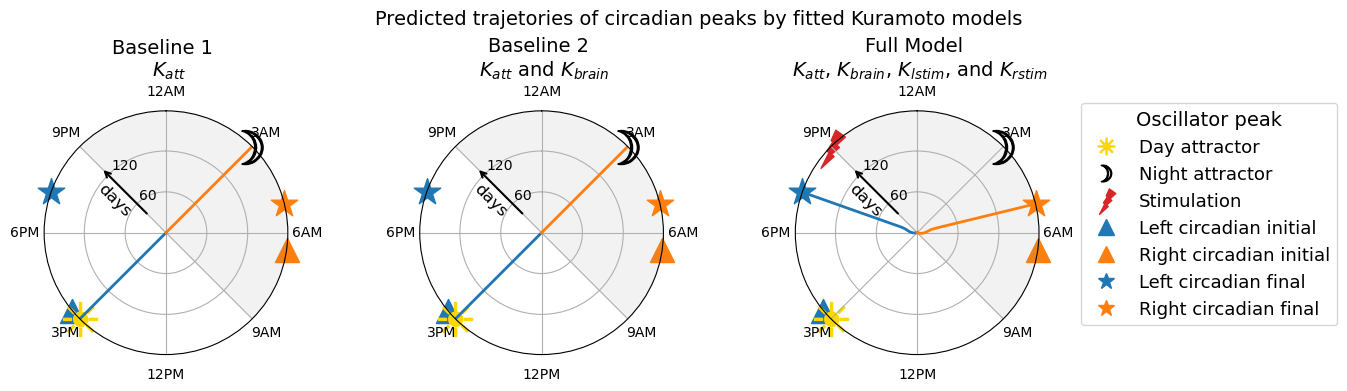

In [13]:
# check Kuramoto model forward solution for a given solution

df_index = 82 # 82
row_dict = {'attractor': acoupdf.loc[df_index], 
            'attractor_brain': abcoupdf.loc[df_index], 
            'attractor_brain_stim': abstcoupdf.loc[df_index]}
row_key_list = list(row_dict.keys())

traj_hue_dict = {'attractor': ['left', 'right'], 'attractor_brain': ['left', 'right'], 
                 'attractor_brain_stim': ['left', 'right']}
subtitle_dict = {'attractor': 'Baseline 1 \n $K_{att}$', 'attractor_brain': 'Baseline 2 \n $K_{att}$ and $K_{brain}$', 
                 'attractor_brain_stim': 'Full Model \n $K_{att}$, $K_{brain}$, $K_{lstim}$, and $K_{rstim}$'}
scaling_list = [1, 1, 1]  # change to [1,1,1] for non scaled version' [80, 300, 5] for index=82

ncols = 4
nrows = 1
fig, ax = plt.subplots(nrows, ncols, figsize=(3.6*ncols, 3.8*nrows), subplot_kw={'projection':'polar'}, layout='constrained')
fax = ax.flatten()

for ii in range(3):
    ### key and row
    row_key = row_key_list[ii]
    row = row_dict[row_key].copy()

    ### Kuramoto model forward solution
    # initial and final peak hours ground truth
    init_thetas = -1 * row[['left_peakphase_prev', 'right_peakphase_prev', 'stim_peakphase']] # negative sign so that the peak occurs at the correct phase
    init_thetas.rename(index={'left_peakphase_prev':'theta_left_0', 'right_peakphase_prev':'theta_right_0', 'stim_peakphase':'theta_stim_0'}, 
                       inplace=True)
    init_thetas = init_thetas.to_dict() | {'omega_0':2*np.pi}
    
    gt_theta_left_final = row['left_peakphase'].item()
    gt_theta_right_final = row['right_peakphase'].item()
    
    # fit coupling constants
    fitted_couplings = row[coupling_const_list].to_dict()
    scaled_fitted_couplings = ( pd.Series(fitted_couplings) / scaling_list[ii] ).to_dict()
    
    # run model forward with fitted coupling constants
    osppdf, outmat, clusmat, ssterm = kuramotoattractor.test_couplings_with_forward_model(theta_init_dict=init_thetas, 
                                                                                          coupling_dict=scaled_fitted_couplings)

    #### plot the trajectories
    cycleviz.kuramoto_forward_trajectories(osppdf, hue_list=traj_hue_dict[row_key], hue_colors=osccolordict,
                                           theta_left=-init_thetas['theta_left_0'], theta_right=-init_thetas['theta_right_0'], 
                                           fig=fig, ax=fax[ii], legend=False, markersize=300)
    
    # plot the final ground truth hour 
    rmax = fax[ii].get_rmax()
    fax[ii].scatter(gt_theta_left_final, rmax, s=400, c='tab:blue', marker='*', clip_on=False)
    fax[ii].scatter(gt_theta_right_final, rmax, s=400, c='tab:orange', marker='*', clip_on=False)

    fax[ii].scatter(dayclus_peakphase, rmax, s=600, c=osccolordict['cday'], marker=sunmarker, clip_on=False)
    fax[ii].scatter(nightclus_peakphase, rmax, s=600, c=osccolordict['cnight'], marker=moonmarker, clip_on=False)

    if row_key == 'attractor_brain_stim': fax[ii].scatter(-init_thetas['theta_stim_0'], rmax, s=900, c=osccolordict['stim'], marker=cycleviz.lightning_bolt(), clip_on=False)

    fax[ii].set_title(subtitle_dict[row_key], fontsize=14)
    fax[ii].set_yticks([60, 120])

    # draw an arrow from the center outward along the 9 PM direction
    fax[ii].set_rlabel_position(-42)
    theta_9pm_rad = 21 * np.pi/12
    fax[ii].annotate('', xy=(theta_9pm_rad, rmax * 0.75), xytext=(theta_9pm_rad, rmax * 0.20),
                      xycoords='data', textcoords='data', arrowprops=dict(arrowstyle='->', lw=1.5, color='black'))
    fax[ii].text(0.96*theta_9pm_rad, rmax * 0.50, 'days', ha='center', va='center', fontsize=12, rotation=-45)

fax[3].set_visible(False)
fig.suptitle(f'Predicted trajetories of circadian peaks by fitted Kuramoto models', fontsize=14)

### fancy legend
# Define the styles and the separate labels
markers = [sunmarker, moonmarker, cycleviz.lightning_bolt(), '^', '^', '*', '*']
colors = [osccolordict[key] for key in ['cday', 'cnight', 'stim', 'left', 'right', 'left', 'right']]
legend_labels = ['Day attractor', 'Night attractor', 'Stimulation', 'Left circadian initial', 'Right circadian initial', 
                 'Left circadian final', 'Right circadian final']

# Create a list to store the custom handles
custom_handles = []
for marker, color in zip(markers, colors):
    # Create a Line2D object with the desired properties
    if color == 'tab:red': markersize=20
    else: markersize=12
    handle = Line2D([0], [0], marker=marker, color=color, linestyle='', markersize=markersize, markerfacecolor=color)
    custom_handles.append(handle)

# We pass the manually created custom_handles and the separate legend_labels
fig.legend(custom_handles, legend_labels, fontsize=13, loc='center right', bbox_to_anchor=(0.95, 0.45), 
           title='Oscillator peak', title_fontsize=14, fancybox=True, shadow=False)

if save_flag:
    plt.savefig(outsupfig_dir + 'kuramoto_example_unscaled.pdf', dpi=300)

plt.show()

### Supplementary: Model comparisons

In [14]:
km_comp_list = [('attractor', 'attractor_brain'), 
                ('attractor', 'attractor_brain_stim'), 
                ('attractor_brain', 'attractor_brain_stim')]

print('Mann-Whitney U tests')
for col1, col2 in km_comp_list:
    print( f'{col1} vs {col2}: P = {mannwhitneyu(fcsimhrdf[col1].dropna(), fcsimhrdf[col2].dropna()).pvalue}')

print('\nWilcoxon paired tests')
fcsimhrdf_common = fcsimhrdf.dropna(axis=0, how='any')
for col1, col2 in km_comp_list:
    print( f'{col1} vs {col2}: P = {wilcoxon(fcsimhrdf_common[col1], fcsimhrdf_common[col2]).pvalue}' )

Mann-Whitney U tests
attractor vs attractor_brain: P = 0.4957650270962908
attractor vs attractor_brain_stim: P = 0.0002074496115202411
attractor_brain vs attractor_brain_stim: P = 0.0001307359437950362

Wilcoxon paired tests
attractor vs attractor_brain: P = 0.015807373095109434
attractor vs attractor_brain_stim: P = 3.4733766381715794e-05
attractor_brain vs attractor_brain_stim: P = 4.867878527972987e-05


attractor vs. attractor_brain: Wilcoxon test (paired samples), P_val:1.581e-02 Stat=4.240e+02
attractor_brain vs. attractor_brain_stim: Wilcoxon test (paired samples), P_val:4.868e-05 Stat=4.351e+03
attractor vs. attractor_brain_stim: Wilcoxon test (paired samples), P_val:3.473e-05 Stat=4.303e+03


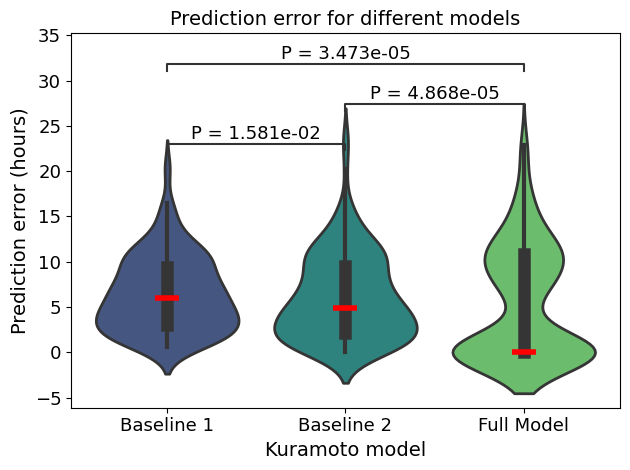

In [15]:
boxdf = fcsimhrdf_common.copy()

boxorder = ['attractor', 'attractor_brain', 'attractor_brain_stim']
boxtickdict = {'attractor': 'Baseline 1', 'attractor_brain':'Baseline 2', 'attractor_brain_stim': 'Full Model'}
boxpairs = [('attractor', 'attractor_brain'), ('attractor', 'attractor_brain_stim'), ('attractor_brain', 'attractor_brain_stim')]

ax = sns.violinplot(data=boxdf, order=boxorder, linewidth=2, palette='viridis')  # boxes

# Iterate through the lines in the plot to find and modify the median lines
vpmedianlist = []
for line in ax.lines:
    if len(line.get_ydata()) == 1:
        vpmedianlist.append( [line.get_xdata()[0], line.get_ydata()[0]] )
# highlight medians
ax.scatter(np.array(vpmedianlist)[:,0], np.array(vpmedianlist)[:,1], c='red', s=300, 
           marker='_', linewidth=4, zorder=3)


ax.set_xlabel('Kuramoto model', fontsize=14)
ax.set_ylabel('Prediction error (hours)', fontsize=14)
ax.set_title('Prediction error for different models', fontsize=14)

ax.set_xticks(ticks=[0,1,2], labels=[boxtickdict[key] for key in boxorder], fontsize=13)
ax.tick_params(labelsize=13)


annotator = Annotator(ax, boxpairs, data=boxdf, order=boxorder)
annotator.configure(test='Wilcoxon', text_format='full', show_test_name=False, loc='inside', 
                    fontsize=13, p_capitalized=True)
annotator.apply_and_annotate()

plt.tight_layout()

if save_flag:
    plt.savefig(outsupfig_dir + 'kuramoto_model_perf_violin.pdf', dpi=300)


plt.show()

In [16]:
print( fcsimhrdf_common['attractor_brain_stim'].median() )
print( fcsimhrdf_common.loc[fcsimhrdf_common['attractor_brain_stim'] > 1]['attractor_brain_stim'].median() )

0.0206032576543611
10.968787667153794


### 6D: Performance comparisons

In [17]:
fcsim_hour_threshold = 1

## percentage of samples that were fit perfectly
count_perfect_sr = ( (fcsimhrdf < fcsim_hour_threshold) & (~fcsimhrdf.isna()) ).sum()
perc_perfect_sr = 100 * count_perfect_sr / fcsimhrdf.shape[0]
perc_perfect_sr = perc_perfect_sr.reset_index(name='perc')
perc_perfect_sr.rename(columns={'index':'model'}, inplace=True)

## total counts of perfectly fit samples
# total_perfect_num = ( (fcsimhrdf < fcsim_hour_threshold) & (~fcsimhrdf.isna()) ).sum().sum()
total_sample_num = fcsimhrdf.shape[0]

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

attractor vs. attractor_brain: Custom statistical test, P_val:9.015e-02
attractor_brain vs. attractor_brain_stim: Custom statistical test, P_val:5.854e-16
attractor vs. attractor_brain_stim: Custom statistical test, P_val:8.534e-21


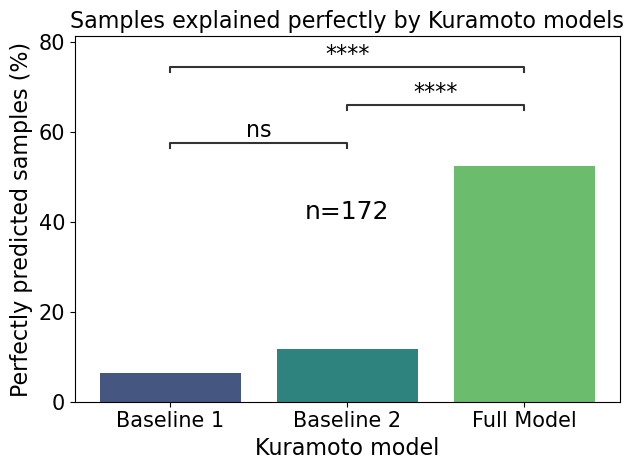

In [18]:
barorder = ['attractor', 'attractor_brain', 'attractor_brain_stim']
bartickdict = {
    'attractor': 'Baseline 1',
    'attractor_brain': 'Baseline 2',
    'attractor_brain_stim': 'Full Model',
}

# Construct pair definitions matching hue comparisons
barpairs = [
    (('attractor', 'attractor_brain')),
    (('attractor_brain', 'attractor_brain_stim')),
    (('attractor', 'attractor_brain_stim')),
]

### p-value from Z-test
perf_comp_pvalues = [proportions_ztest(count=[count_perfect_sr[item[0]], count_perfect_sr[item[1]]], nobs=total_sample_num)[1] 
                     for item in barpairs]

### plot the data
ax = sns.barplot(perc_perfect_sr, x='model', y='perc', hue='model',
                 order=barorder, palette='viridis', legend=False)

# dummy bar to show all the annotations above the tallest bar
for xi in range(len(barorder)):
    ax.scatter([xi], [53], alpha=0)

## annotator
# Initialize annotator
annotator = Annotator(
    ax, pairs=barpairs, data=perc_perfect_sr, x='model', y='perc', order=barorder, plot='barplot'
)

# Configure using a dummy test string (required by statannotations for formatting)
annotator.configure(test=None, text_format='star', test_short_name='Z-test', loc='inside', 
                    fontsize=16, p_capitalized=True)

# Pass custom p-values array and call annotate() directly
annotator.set_pvalues(perf_comp_pvalues)
annotator.annotate()

### number of samples
ax.text(x=0.5,y=0.5, s=f'n={total_sample_num}', ha='center', transform=ax.transAxes, fontsize=18)

## aesthetics
ax.set_xlabel('Kuramoto model', fontsize=16)
ax.set_ylabel('Perfectly predicted samples (%)', fontsize=16)
ax.set_title('Samples explained perfectly by Kuramoto models', fontsize=16)

ax.set_xticks(
    ticks=[0, 1, 2], labels=[bartickdict[key] for key in barorder], fontsize=15
)
ax.tick_params(labelsize=15)

plt.tight_layout()

if save_flag:
    plt.savefig(outfig_dir + 'kuramoto_perf_bar.pdf', dpi=300)

plt.show()

In [19]:
print('Pvalues for Z-test:', dict(zip(barpairs, perf_comp_pvalues)))

Pvalues for Z-test: {('attractor', 'attractor_brain'): 0.0901502064191566, ('attractor_brain', 'attractor_brain_stim'): 5.853939236526614e-16, ('attractor', 'attractor_brain_stim'): 8.534291607435661e-21}


### Supplement: Performance difference across outcomes

In [20]:
def resptype_extremes(szred):
    if szred < 0.5:
        return 'NR'
    elif szred > 0.9:
        return 'SR'
    else:
        return np.NaN

In [21]:
### show the model performance for different seizure reductions
kmoutdf = fcsimhrdf.copy()
kmoutdf = pd.concat((abstcoupdf[['npecode', 'dur_day']], kmoutdf), axis=1, ignore_index=False)  # patient code and date
kmoutdf['band'] = 'alpha'  # include dummy information for comptability with function
kmoutdf.rename(columns={'dur_day':'days_from_implant'}, inplace=True)  # rename for compatibility with next function
kmoutdf = ccutils.closest_outcome_and_feature_df(lgpatcodesdf, kmoutdf, patient_list, timelock_type='causal')  # align with outcome

kmoutdf = kmoutdf.loc[kmoutdf['outcome_feat_gap'] < 365].copy()  # within 1 yr
# kmoutdf['Responder_Type'] = kmoutdf['sz_red'].apply(lambda x: 'NR' if x < 0.5 else 'SR+IR')
kmoutdf['Responder_Type'] = kmoutdf['sz_red'].apply(lambda x: resptype_extremes(x))

print('Validation checks. Min gap: %d, Max gap: %d'% (kmoutdf['outcome_feat_gap'].min(), kmoutdf['outcome_feat_gap'].max()) )

# melt for boxplots
kmoutdf = kmoutdf.melt(id_vars=['npecode', 'feat_days', 'sz_red', 'Responder_Type'], 
                       value_vars=['attractor', 'attractor_brain', 'attractor_brain_stim'], 
                       var_name='model', value_name='fc_sim_hr')
# drop nans
kmoutdf.dropna(inplace=True)

Validation checks. Min gap: 0, Max gap: 338


attractor_brain_NR vs. attractor_brain_SR: Mann-Whitney-Wilcoxon test two-sided, P_val:1.975e-01 U_stat=1.670e+02


attractor_NR vs. attractor_SR: Mann-Whitney-Wilcoxon test two-sided, P_val:3.595e-02 U_stat=1.350e+02
attractor_brain_stim_NR vs. attractor_brain_stim_SR: Mann-Whitney-Wilcoxon test two-sided, P_val:8.795e-01 U_stat=2.120e+02


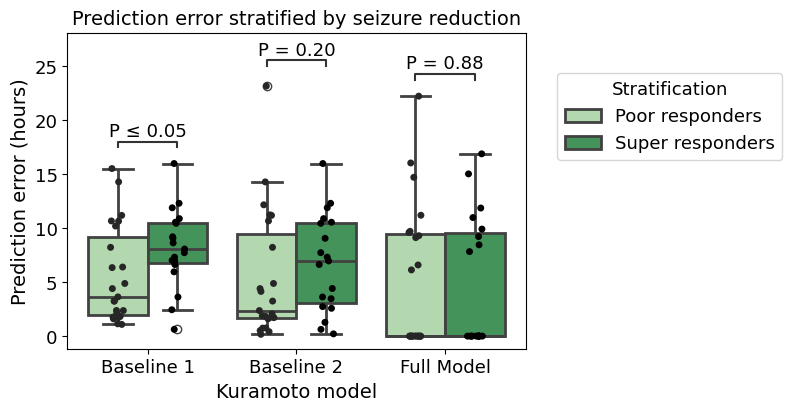

In [22]:
moboxorder = ['attractor', 'attractor_brain', 'attractor_brain_stim']   # model - outcome boxdf
mohueorder = ['NR', 'SR']

moboxpairs = [((mod, mohueorder[0]), (mod, mohueorder[1])) for mod in moboxorder]

fig, ax = plt.subplots(1,1,figsize=(7.8,4), layout='constrained')

# boxplot
ax = sns.boxplot(data=kmoutdf, x='model', y='fc_sim_hr', hue='Responder_Type', 
                 order=moboxorder, hue_order=mohueorder, linewidth=2, palette='Greens')
# strip plot
sns.stripplot(data=kmoutdf, x='model', y='fc_sim_hr', hue='Responder_Type', 
              order=moboxorder, hue_order=mohueorder, dodge=True, palette='dark:k', ax=ax, legend=False)

# statistical annotations
annotator = Annotator(ax, moboxpairs, data=kmoutdf, x='model', y='fc_sim_hr', hue='Responder_Type', 
                      order=moboxorder, hue_order=mohueorder)
annotator.configure(test='Mann-Whitney', text_format='simple', show_test_name=False, loc='inside', 
                    fontsize=13, p_capitalized=True)   # possible tests: 't-test_ind' or 'Mann-Whitney' 
annotator.apply_and_annotate()


# format legend
moleghan, moleglab = ax.get_legend_handles_labels()
moleglab = ['Poor responders', 'Super responders']
ax.legend(moleghan, moleglab, loc='upper left', title='Stratification', 
          fontsize=13, title_fontsize=13, bbox_to_anchor=(1.05,0.9))

# aesthetics
ax.set_xlabel('Kuramoto model', fontsize=14)
ax.set_ylabel('Prediction error (hours)', fontsize=14)
ax.set_title('Prediction error stratified by seizure reduction', fontsize=14)

ax.set_xticks(ticks=[0,1,2], labels=[boxtickdict[key] for key in moboxorder], fontsize=13)
ax.tick_params(labelsize=13)

if save_flag:
    plt.savefig(outsupfig_dir + 'kuramoto_fit_vs_outcomes.pdf', dpi=300)

plt.show()